# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
# Load the cleaned dataset created by Aviation_Accidents_Cleaning.ipynb.
from pathlib import Path

CLEAN_PATH = Path("data/aviation_accidents_cleaned.csv")
if not CLEAN_PATH.exists():
    CLEAN_PATH = Path("../data/aviation_accidents_cleaned.csv")
df = pd.read_csv(CLEAN_PATH, low_memory=False)
df["Event.Date"] = pd.to_datetime(df["Event.Date"], errors="coerce")
print("Cleaned data shape:", df.shape)
display(df.head())
display(df[["Fatal.Serious.Fraction", "Aircraft.Destroyed", "Total.Occupants.Reported"]].describe())

Cleaned data shape: (19480, 23)


,Event.Id,Investigation.Type,Event.Date,Injury.Severity,Aircraft.damage,Aircraft.Category,Make,Model,Amateur.Built,Number.of.Engines,...,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Total.Occupants.Reported,Fatal.Serious.Count,Fatal.Serious.Fraction,Aircraft.Destroyed,Make.Model
0,20170710X52551,Accident,1979-09-17,Non-Fatal,Substantial,Airplane,Mcdonnell Douglas,DC9,No,2.0,...,NaN,1.0,44.0,VMC,Climb,45.0,NaN,NaN,0.0,Mcdonnell Douglas | DC9
1,20020909X01562,Accident,1982-01-01,Non-Fatal,Substantial,Airplane,Cessna,140,No,1.0,...,0.0,0.0,2.0,VMC,Takeoff,2.0,0.0,0.0,0.0,Cessna | 140
2,20020909X01561,Accident,1982-01-01,Non-Fatal,Substantial,Airplane,Cessna,401B,No,2.0,...,0.0,0.0,2.0,IMC,Landing,2.0,0.0,0.0,0.0,Cessna | 401B
3,20020917X02148,Accident,1982-01-02,Non-Fatal,Destroyed,Airplane,Bellanca,17-30A,No,1.0,...,0.0,1.0,0.0,IMC,Cruise,1.0,0.0,0.0,1.0,Bellanca | 17-30A
4,20020917X02134,Accident,1982-01-02,Fatal(1),Destroyed,Airplane,Cessna,R172K,No,1.0,...,0.0,0.0,0.0,IMC,Takeoff,1.0,1.0,1.0,1.0,Cessna | R172K


,Fatal.Serious.Fraction,Aircraft.Destroyed,Total.Occupants.Reported
count,16747.000000,19031.000000,19462.000000
mean,0.312204,0.140087,5.720430
std,0.442649,0.347087,27.440446
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,1.000000
50%,0.000000,0.000000,2.000000
75%,1.000000,0.000000,2.000000
max,1.000000,1.000000,576.000000


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [3]:
# Use reported occupants as a proxy for aircraft size because seating capacity is not available in this accident dataset. 

df["Aircraft.Size.Group"] = np.where(
    df["Total.Occupants.Reported"].le(20), "Small (<=20 occupants)",
    "Large (>20 occupants)"
)
# Avoid assigning records with unknown/zero occupants to a size group.
df.loc[df["Total.Occupants.Reported"].isna() | df["Total.Occupants.Reported"].le(0),
       "Aircraft.Size.Group"] = pd.NA

model_summary = (
    df.dropna(subset=["Make.Model", "Aircraft.Size.Group"])
      .groupby(["Aircraft.Size.Group", "Make.Model"], observed=True)
      .agg(
          accident_count=("Event.Id", "size"),
          mean_severe_injury_fraction=("Fatal.Serious.Fraction", "mean"),
          destruction_fraction=("Aircraft.Destroyed", "mean"),
          mean_occupants=("Total.Occupants.Reported", "mean")
      )
      .reset_index()
)
# Models must have at least 10 accident records for more stable comparisons.
model_summary_eligible = model_summary[model_summary["accident_count"] >= 10].copy()
display(model_summary_eligible.sort_values("mean_severe_injury_fraction").head(20))

,Aircraft.Size.Group,Make.Model,accident_count,mean_severe_injury_fraction,destruction_fraction,mean_occupants
849,Small (<=20 occupants),Cessna | 172SP,12,0.000000,0.000000,1.666667
1462,Small (<=20 occupants),Maule | M-5-210C,14,0.000000,0.000000,2.071429
1316,Small (<=20 occupants),Diamond Aircraft Ind Inc | DA 20 C1,11,0.000000,0.000000,1.454545
111,Large (>20 occupants),Boeing | 777,12,0.001826,0.500000,238.916667
81,Large (>20 occupants),Boeing | 757,10,0.002651,0.000000,180.600000
157,Large (>20 occupants),Embraer | EMB-145LR,10,0.016667,0.000000,62.700000
871,Small (<=20 occupants),Cessna | 180J,31,0.040000,0.000000,1.709677
326,Small (<=20 occupants),Air Tractor | AT 602,12,0.041667,0.000000,1.083333
710,Small (<=20 occupants),Boeing | 737,15,0.066667,0.125000,2.800000
1772,Small (<=20 occupants),Piper | PA-20,33,0.071429,0.030303,1.606061


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

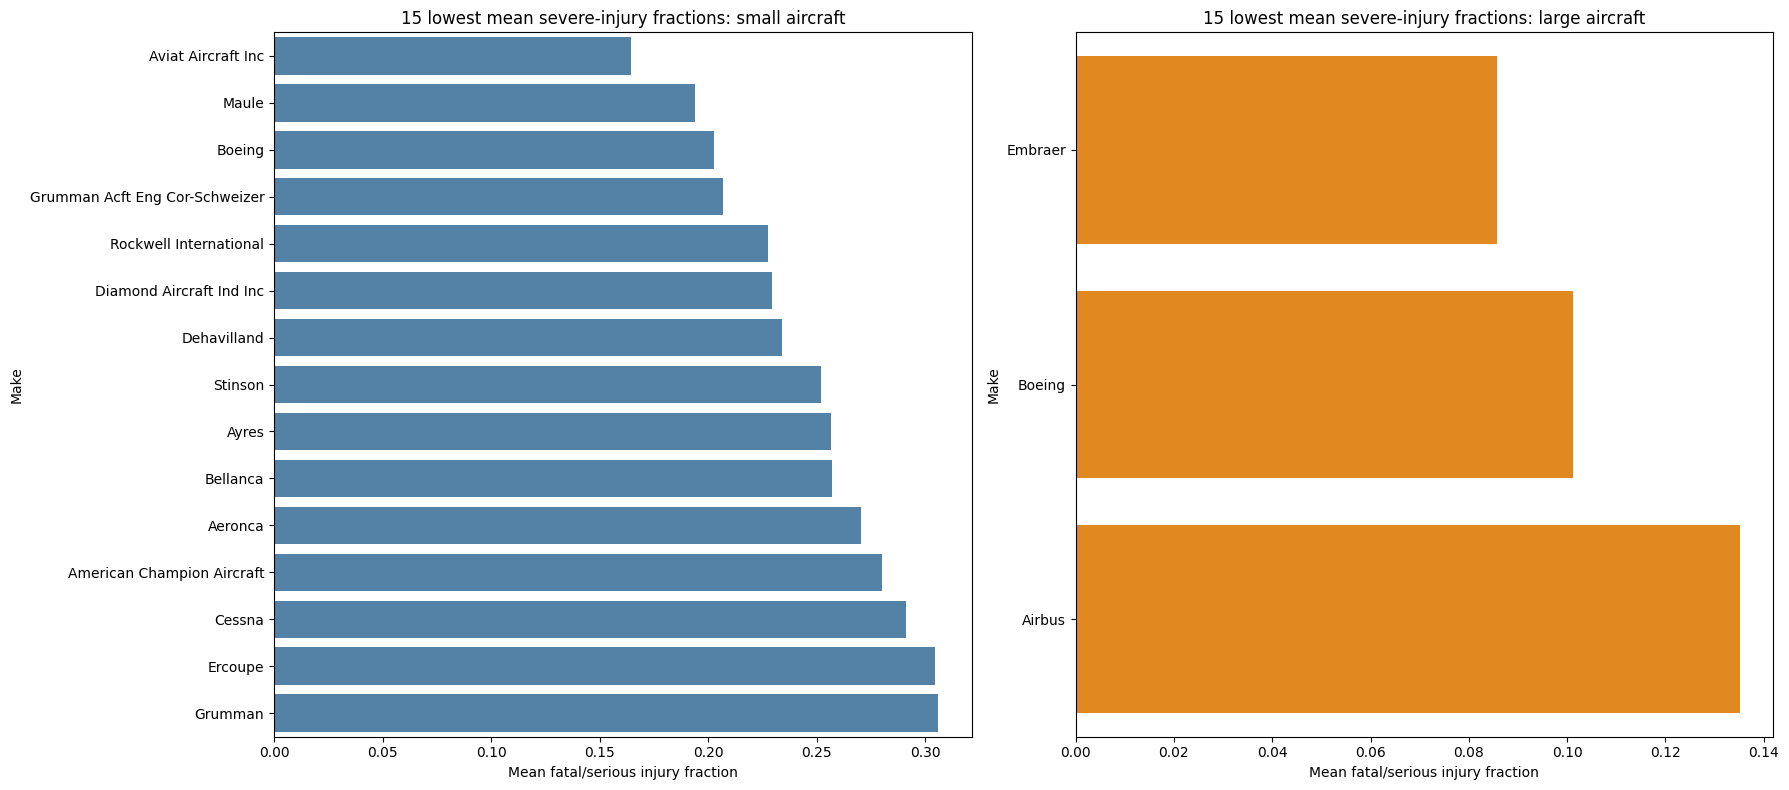

,Aircraft.Size.Group,Make,accident_count,mean_severe_injury_fraction,destruction_fraction
13,Small (<=20 occupants),Aviat Aircraft Inc,76,0.164474,0.040000
30,Small (<=20 occupants),Maule,232,0.193794,0.056034
17,Small (<=20 occupants),Boeing,215,0.202508,0.136842
28,Small (<=20 occupants),Grumman Acft Eng Cor-Schweizer,58,0.206897,0.017241
38,Small (<=20 occupants),Rockwell International,59,0.227679,0.118644
24,Small (<=20 occupants),Diamond Aircraft Ind Inc,72,0.229167,0.055556
23,Small (<=20 occupants),Dehavilland,93,0.234170,0.044444
40,Small (<=20 occupants),Stinson,146,0.251938,0.047945
14,Small (<=20 occupants),Ayres,55,0.256410,0.127273
16,Small (<=20 occupants),Bellanca,280,0.257092,0.100000


,Aircraft.Size.Group,Make,accident_count,mean_severe_injury_fraction,destruction_fraction
4,Large (>20 occupants),Embraer,51,0.085764,0.133333
2,Large (>20 occupants),Boeing,304,0.101187,0.183007
0,Large (>20 occupants),Airbus,68,0.135157,0.250000


In [4]:
# Compare the 15 makes with the lowest average severe-injury fraction in each size group.
make_summary = (
    df.dropna(subset=["Make", "Aircraft.Size.Group"])
      .groupby(["Aircraft.Size.Group", "Make"], observed=True)
      .agg(
          accident_count=("Event.Id", "size"),
          mean_severe_injury_fraction=("Fatal.Serious.Fraction", "mean"),
          destruction_fraction=("Aircraft.Destroyed", "mean")
      )
      .reset_index()
)
make_summary = make_summary[make_summary["accident_count"] >= 50]
small_makes = make_summary[make_summary["Aircraft.Size.Group"] == "Small (<=20 occupants)"].nsmallest(15, "mean_severe_injury_fraction")
large_makes = make_summary[make_summary["Aircraft.Size.Group"] == "Large (>20 occupants)"].nsmallest(15, "mean_severe_injury_fraction")

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
sns.barplot(data=small_makes, y="Make", x="mean_severe_injury_fraction", ax=axes[0], color="steelblue")
axes[0].set_title("15 lowest mean severe-injury fractions: small aircraft")
axes[0].set_xlabel("Mean fatal/serious injury fraction")
sns.barplot(data=large_makes, y="Make", x="mean_severe_injury_fraction", ax=axes[1], color="darkorange")
axes[1].set_title("15 lowest mean severe-injury fractions: large aircraft")
axes[1].set_xlabel("Mean fatal/serious injury fraction")
plt.tight_layout()
plt.show()
display(small_makes)
display(large_makes)

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

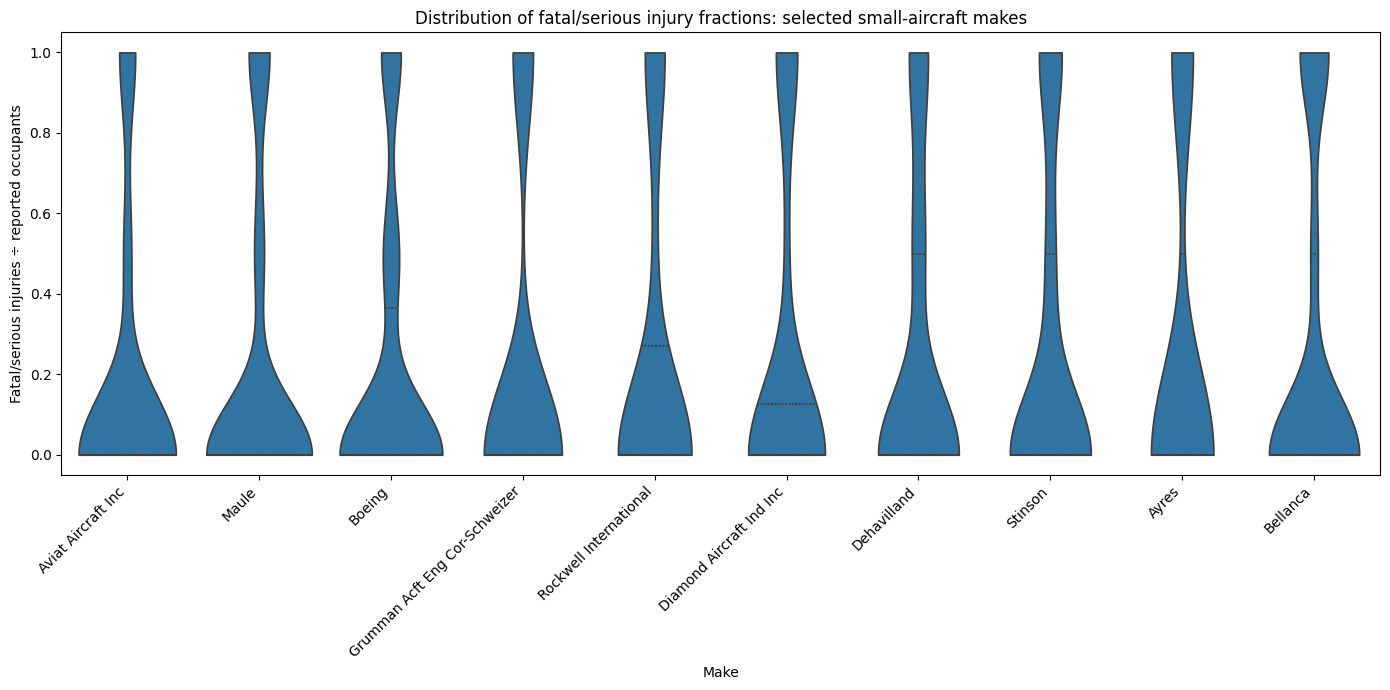

In [5]:
# Distribution of severe-injury fractions for the ten lowest-mean small-aircraft makes.
small_ten = small_makes.nsmallest(10, "mean_severe_injury_fraction")["Make"].tolist()
plot_df = df[
    (df["Aircraft.Size.Group"] == "Small (<=20 occupants)")
    & df["Make"].isin(small_ten)
    & df["Fatal.Serious.Fraction"].notna()
].copy()
plt.figure(figsize=(14, 7))
sns.violinplot(data=plot_df, x="Make", y="Fatal.Serious.Fraction", order=small_ten, cut=0, inner="quartile")
plt.xticks(rotation=45, ha="right")
plt.title("Distribution of fatal/serious injury fractions: selected small-aircraft makes")
plt.xlabel("Make")
plt.ylabel("Fatal/serious injuries ÷ reported occupants")
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

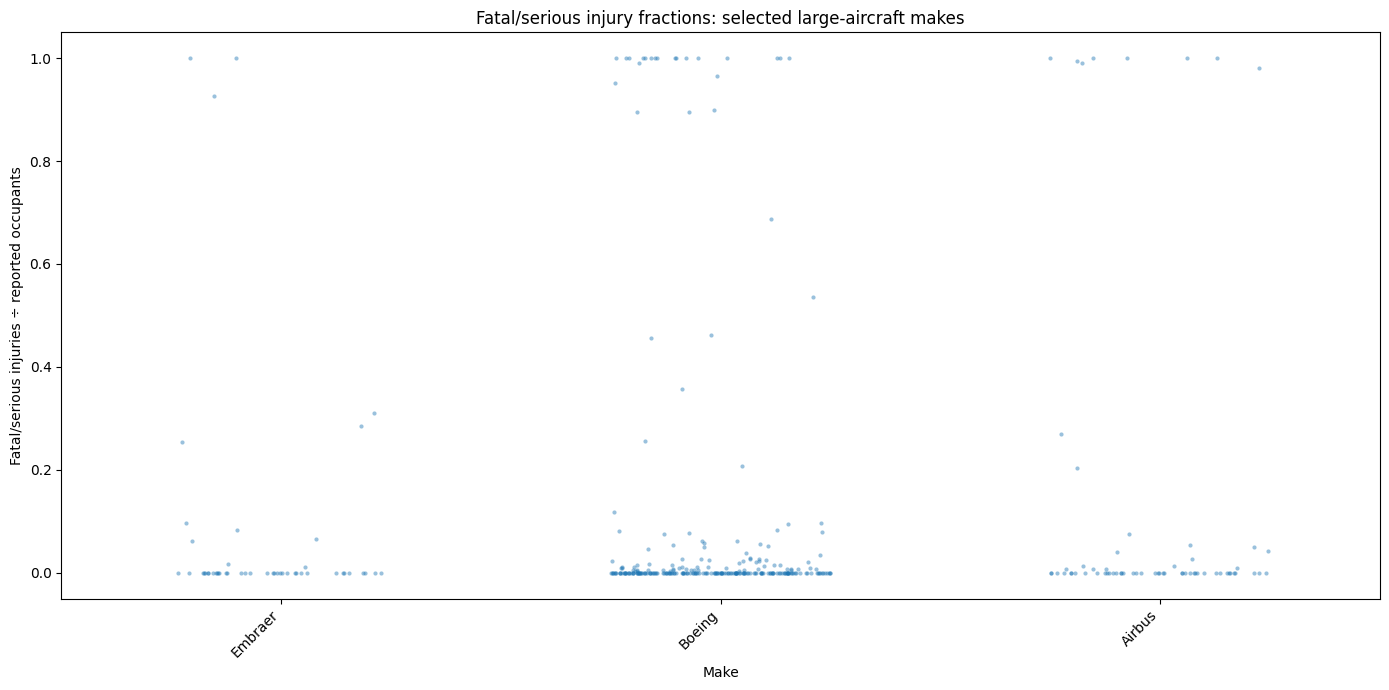

In [6]:
# Distribution of severe-injury fractions for the ten lowest-mean large-aircraft makes.
large_ten = large_makes.nsmallest(10, "mean_severe_injury_fraction")["Make"].tolist()
plot_df = df[
    (df["Aircraft.Size.Group"] == "Large (>20 occupants)")
    & df["Make"].isin(large_ten)
    & df["Fatal.Serious.Fraction"].notna()
].copy()
plt.figure(figsize=(14, 7))
sns.stripplot(data=plot_df, x="Make", y="Fatal.Serious.Fraction", order=large_ten,
              jitter=0.25, alpha=0.45, size=3)
plt.xticks(rotation=45, ha="right")
plt.title("Fatal/serious injury fractions: selected large-aircraft makes")
plt.xlabel("Make")
plt.ylabel("Fatal/serious injuries ÷ reported occupants")
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

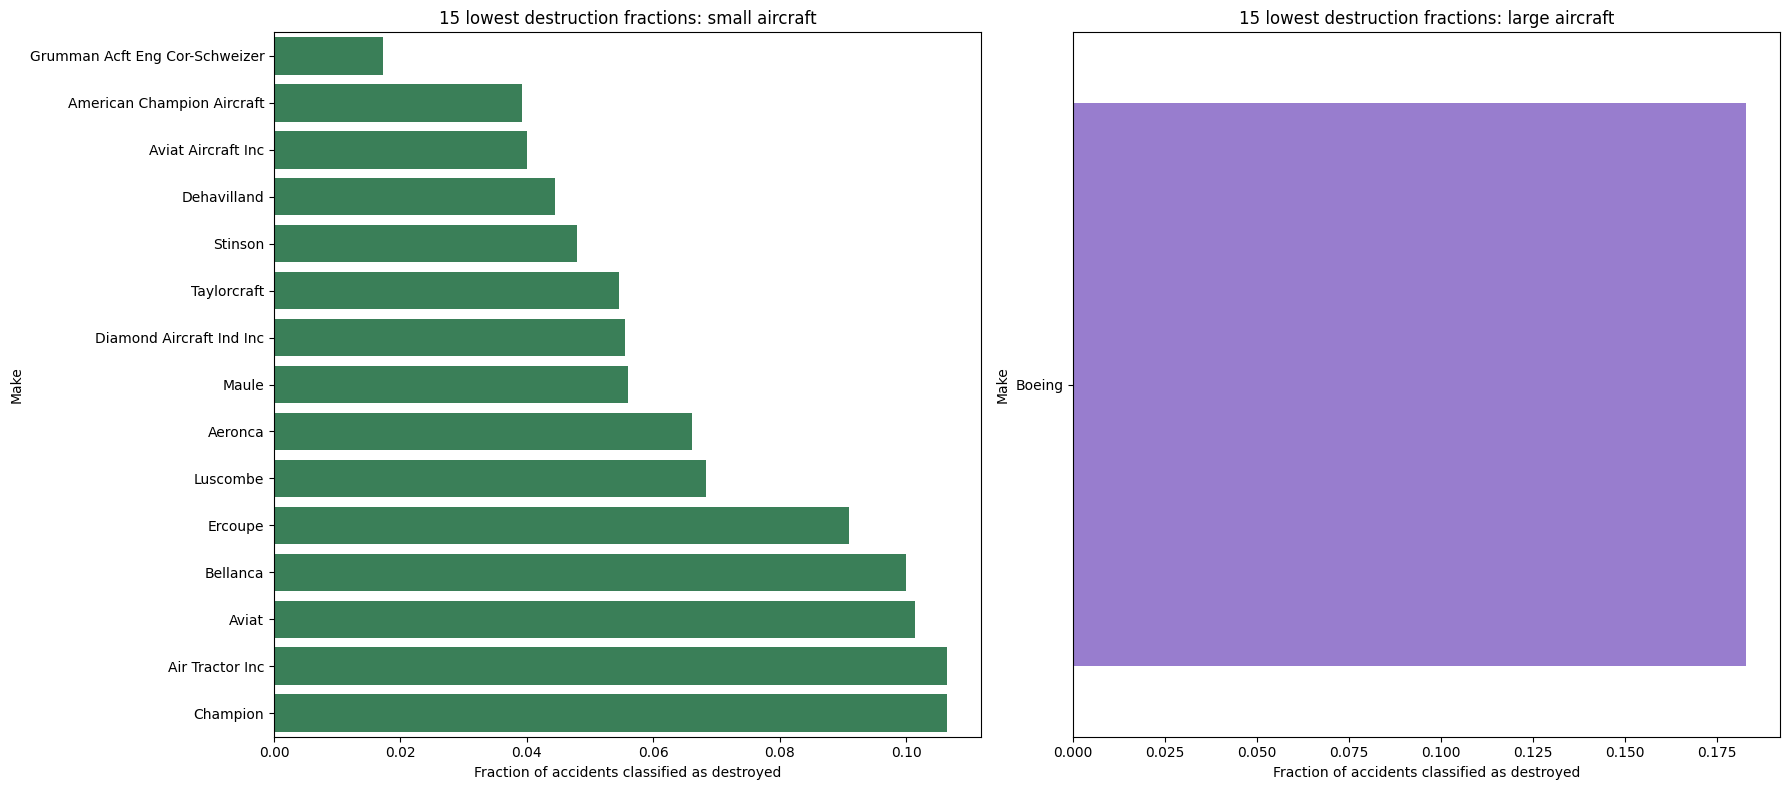

,Aircraft.Size.Group,Make,accident_count,destruction_fraction,mean_severe_injury_fraction
28,Small (<=20 occupants),Grumman Acft Eng Cor-Schweizer,58,0.017241,0.206897
11,Small (<=20 occupants),American Champion Aircraft,51,0.039216,0.280000
13,Small (<=20 occupants),Aviat Aircraft Inc,75,0.040000,0.166667
23,Small (<=20 occupants),Dehavilland,90,0.044444,0.230828
40,Small (<=20 occupants),Stinson,146,0.047945,0.251938
41,Small (<=20 occupants),Taylorcraft,110,0.054545,0.311111
24,Small (<=20 occupants),Diamond Aircraft Ind Inc,72,0.055556,0.229167
30,Small (<=20 occupants),Maule,232,0.056034,0.193794
7,Small (<=20 occupants),Aeronca,227,0.066079,0.270370
29,Small (<=20 occupants),Luscombe,161,0.068323,0.320896


,Aircraft.Size.Group,Make,accident_count,destruction_fraction,mean_severe_injury_fraction
2,Large (>20 occupants),Boeing,153,0.183007,0.199076


In [7]:
# Compare aircraft destruction rates by make and aircraft-size group.
damage_summary = (
    df.dropna(subset=["Make", "Aircraft.Size.Group", "Aircraft.Destroyed"])
      .groupby(["Aircraft.Size.Group", "Make"], observed=True)
      .agg(accident_count=("Event.Id", "size"),
           destruction_fraction=("Aircraft.Destroyed", "mean"),
           mean_severe_injury_fraction=("Fatal.Serious.Fraction", "mean"))
      .reset_index()
)
damage_summary = damage_summary[damage_summary["accident_count"] >= 50]
small_damage = damage_summary[damage_summary["Aircraft.Size.Group"] == "Small (<=20 occupants)"].nsmallest(15, "destruction_fraction")
large_damage = damage_summary[damage_summary["Aircraft.Size.Group"] == "Large (>20 occupants)"].nsmallest(15, "destruction_fraction")
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
sns.barplot(data=small_damage, y="Make", x="destruction_fraction", ax=axes[0], color="seagreen")
axes[0].set_title("15 lowest destruction fractions: small aircraft")
sns.barplot(data=large_damage, y="Make", x="destruction_fraction", ax=axes[1], color="mediumpurple")
axes[1].set_title("15 lowest destruction fractions: large aircraft")
for ax in axes:
    ax.set_xlabel("Fraction of accidents classified as destroyed")
plt.tight_layout()
plt.show()
display(small_damage)
display(large_damage)

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

#### Findings and recommendations by make
The charts rank makes using the mean fatal/serious injury fraction and the fraction of accidents where the aircraft was classified as destroyed. These are descriptive comparisons among recorded accidents, not accident rates per flight or flight-hour; makes with more accidents may differ in age, mission, operating environment, and exposure. The 50-accident minimum reduces (but does not remove) instability from small samples.

For a practical shortlist, prioritize makes that appear favorably on both injury fraction and destruction fraction, then review the sample size and operating context before making an insurance or fleet decision. A low average injury fraction alone is insufficient if the destruction fraction is high. Results should be treated as screening evidence rather than proof that a manufacturer is inherently safer.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

,Aircraft.Size.Group,Make.Model,accident_count,mean_severe_injury_fraction,destruction_fraction,mean_occupants
111,Large (>20 occupants),Boeing | 777,12,0.001826,0.500000,238.916667
81,Large (>20 occupants),Boeing | 757,10,0.002651,0.000000,180.600000
157,Large (>20 occupants),Embraer | EMB-145LR,10,0.016667,0.000000,62.700000
46,Large (>20 occupants),Boeing | 737 7H4,12,0.079474,0.000000,137.083333
95,Large (>20 occupants),Boeing | 767,18,0.080531,0.125000,177.944444
36,Large (>20 occupants),Boeing | 737,77,0.173053,0.207547,134.168831
11,Large (>20 occupants),Airbus | A320,11,0.200577,0.600000,143.181818


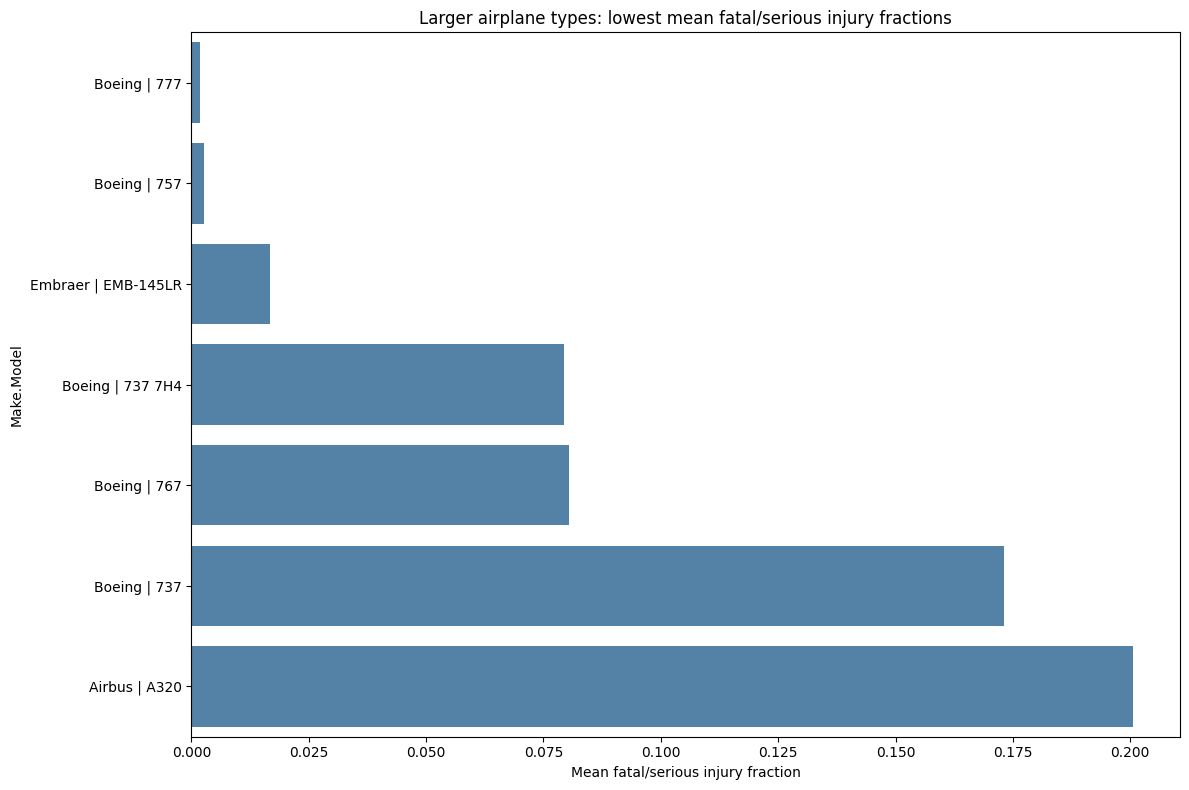

Potential large-aircraft candidates (at least 10 accident records):


,Make.Model,accident_count,mean_severe_injury_fraction,destruction_fraction
111,Boeing | 777,12,0.001826,0.500000
81,Boeing | 757,10,0.002651,0.000000
157,Embraer | EMB-145LR,10,0.016667,0.000000
46,Boeing | 737 7H4,12,0.079474,0.000000
95,Boeing | 767,18,0.080531,0.125000
36,Boeing | 737,77,0.173053,0.207547
11,Airbus | A320,11,0.200577,0.600000


In [8]:
# Model-level results for larger aircraft (>20 reported occupants).

large_models = model_summary_eligible[
    model_summary_eligible["Aircraft.Size.Group"] == "Large (>20 occupants)"
].sort_values("mean_severe_injury_fraction")
display(large_models.head(20))
top_large = large_models.head(15)
if len(top_large):
    fig, ax = plt.subplots(figsize=(12, 8))
    sns.barplot(data=top_large, y="Make.Model", x="mean_severe_injury_fraction", ax=ax, color="steelblue")
    ax.set_title("Larger airplane types: lowest mean fatal/serious injury fractions")
    ax.set_xlabel("Mean fatal/serious injury fraction")
    plt.tight_layout()
    plt.show()
else:
    print("No large model has enough usable injury data to support a stable ranking.")

if len(top_large):
    print("Potential large-aircraft candidates (at least 10 accident records):")
    display(top_large[["Make.Model", "accident_count", "mean_severe_injury_fraction", "destruction_fraction"]])
else:
    print("No large-aircraft model met the 10-record threshold in this cleaned sample.")

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

,Aircraft.Size.Group,Make.Model,accident_count,mean_severe_injury_fraction,destruction_fraction,mean_occupants
849,Small (<=20 occupants),Cessna | 172SP,12,0.000000,0.000000,1.666667
1462,Small (<=20 occupants),Maule | M-5-210C,14,0.000000,0.000000,2.071429
1316,Small (<=20 occupants),Diamond Aircraft Ind Inc | DA 20 C1,11,0.000000,0.000000,1.454545
871,Small (<=20 occupants),Cessna | 180J,31,0.040000,0.000000,1.709677
326,Small (<=20 occupants),Air Tractor | AT 602,12,0.041667,0.000000,1.083333
710,Small (<=20 occupants),Boeing | 737,15,0.066667,0.125000,2.800000
1772,Small (<=20 occupants),Piper | PA-20,33,0.071429,0.030303,1.606061
473,Small (<=20 occupants),Beech | 76,26,0.072917,0.076923,2.192308
908,Small (<=20 occupants),Cessna | 185F,11,0.083333,0.181818,2.636364
2110,Small (<=20 occupants),Stinson | 108-1,19,0.083333,0.000000,1.578947


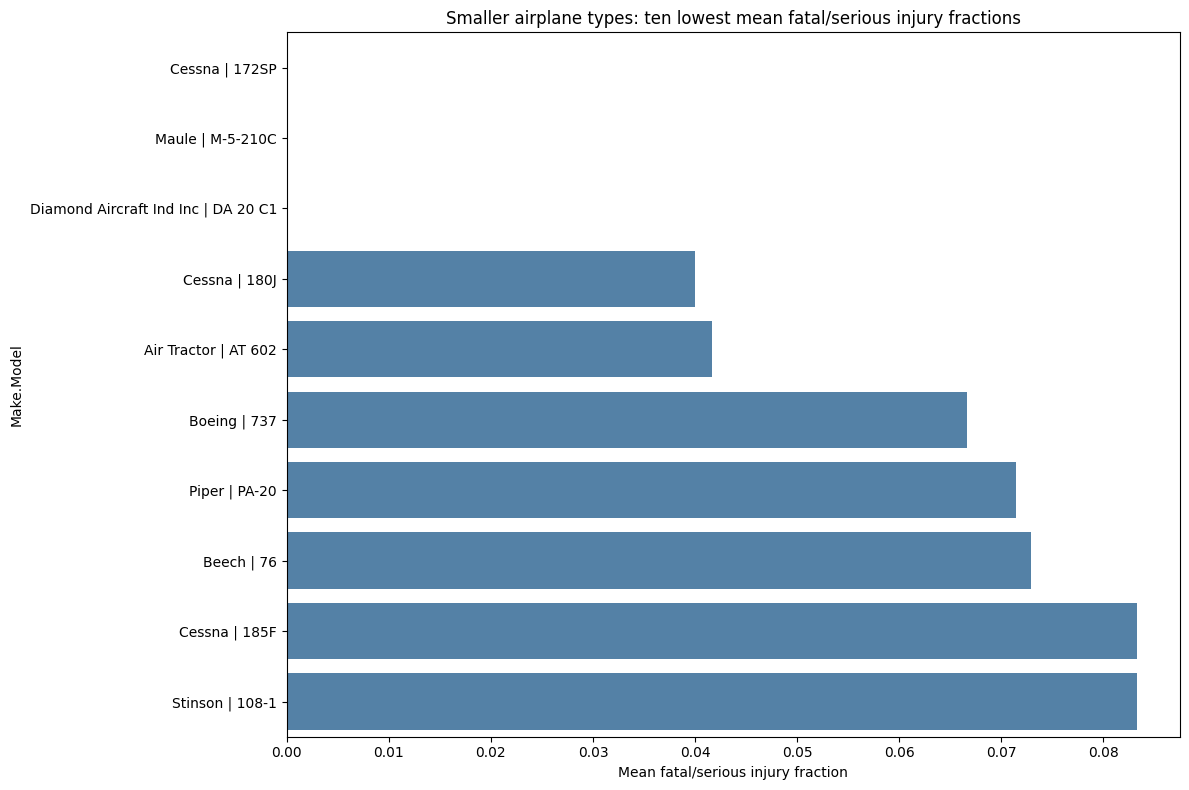

,Make.Model,accident_count,mean_severe_injury_fraction,destruction_fraction
849,Cessna | 172SP,12,0.000000,0.000000
1462,Maule | M-5-210C,14,0.000000,0.000000
1316,Diamond Aircraft Ind Inc | DA 20 C1,11,0.000000,0.000000
871,Cessna | 180J,31,0.040000,0.000000
326,Air Tractor | AT 602,12,0.041667,0.000000
710,Boeing | 737,15,0.066667,0.125000
1772,Piper | PA-20,33,0.071429,0.030303
473,Beech | 76,26,0.072917,0.076923
908,Cessna | 185F,11,0.083333,0.181818
2110,Stinson | 108-1,19,0.083333,0.000000


In [9]:
# Model-level results for smaller aircraft (<=20 reported occupants).

small_models = model_summary_eligible[
    model_summary_eligible["Aircraft.Size.Group"] == "Small (<=20 occupants)"
].sort_values("mean_severe_injury_fraction")
display(small_models.head(20))
top_small = small_models.head(10)
if len(top_small):
    fig, ax = plt.subplots(figsize=(12, 8))
    sns.barplot(data=top_small, y="Make.Model", x="mean_severe_injury_fraction", ax=ax, color="steelblue")
    ax.set_title("Smaller airplane types: ten lowest mean fatal/serious injury fractions")
    ax.set_xlabel("Mean fatal/serious injury fraction")
    plt.tight_layout()
    plt.show()
else:
    print("No small model has enough usable injury data to support a stable ranking.")
if len(top_small):
    display(top_small[["Make.Model", "accident_count", "mean_severe_injury_fraction", "destruction_fraction"]])
else:
    print("No small-aircraft model met the 10-record threshold in this cleaned sample.")

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

The model tables provide a more specific shortlist than make-level averages because the same manufacturer may produce aircraft with very different capacities and designs. For both size groups, compare the injury fraction alongside the destruction fraction and accident count. Models with fewer than ten recorded accidents are excluded to avoid recommending a type based on a very small sample.

The “large” and “small” labels are based on reported occupants in each accident, not certified seating capacity. They are therefore analytical proxies and can misclassify an aircraft when occupant counts are missing or unusually low. These rankings should be validated against fleet exposure, aircraft age, routes, and operational data before being used for purchasing, underwriting, or safety policy.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.


Weather condition: summary (groups with at least 100 accidents)


,Weather.Condition,accident_count,mean_severe_injury_fraction,destruction_fraction
0,IMC,1135,0.659823,0.442727
1,UNK,148,0.591149,0.421488
2,VMC,16557,0.262260,0.100300


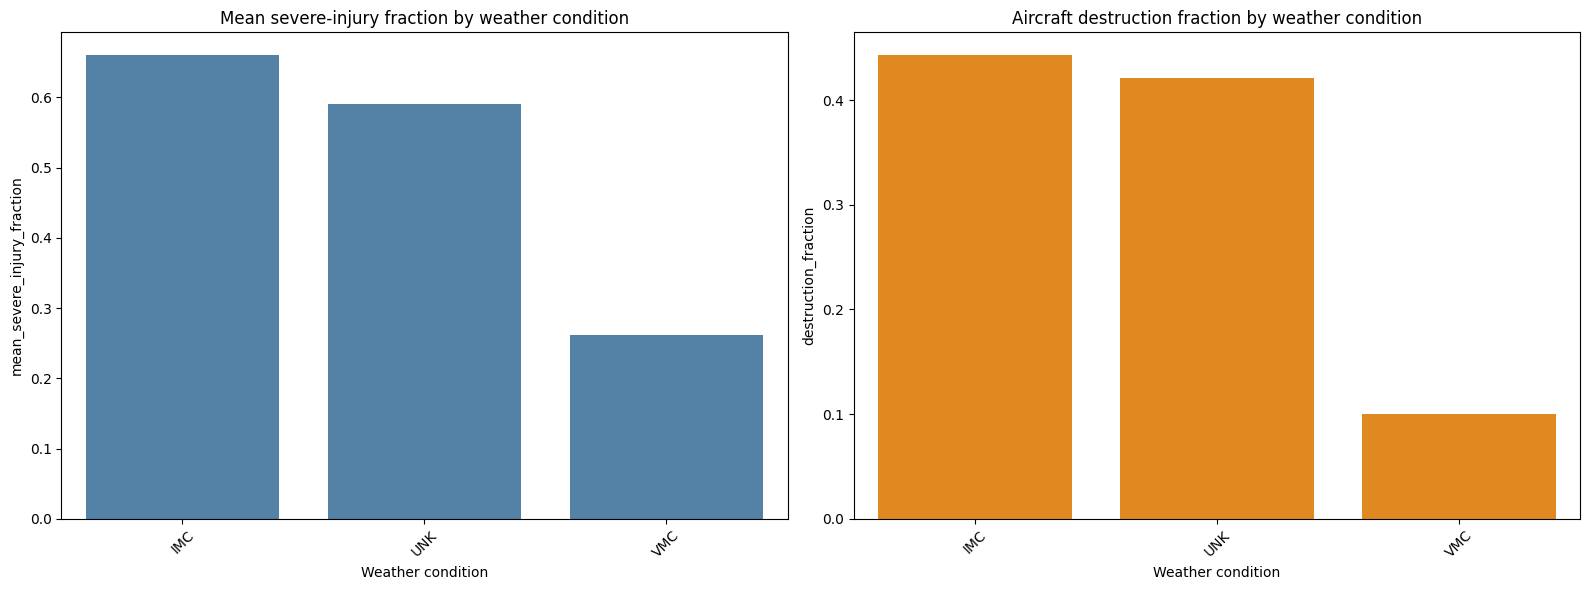


Phase of flight: summary (groups with at least 100 accidents)


,Broad.phase.of.flight,accident_count,mean_severe_injury_fraction,destruction_fraction
6,Maneuvering,397,0.545189,0.492424
1,Climb,119,0.445407,0.417391
2,Cruise,690,0.418485,0.343612
3,Descent,136,0.361739,0.287879
0,Approach,494,0.343505,0.219067
4,Go-Around,135,0.320988,0.170370
9,Takeoff,977,0.234760,0.213552
5,Landing,1872,0.041518,0.042201
10,Taxi,197,0.011429,0.026178


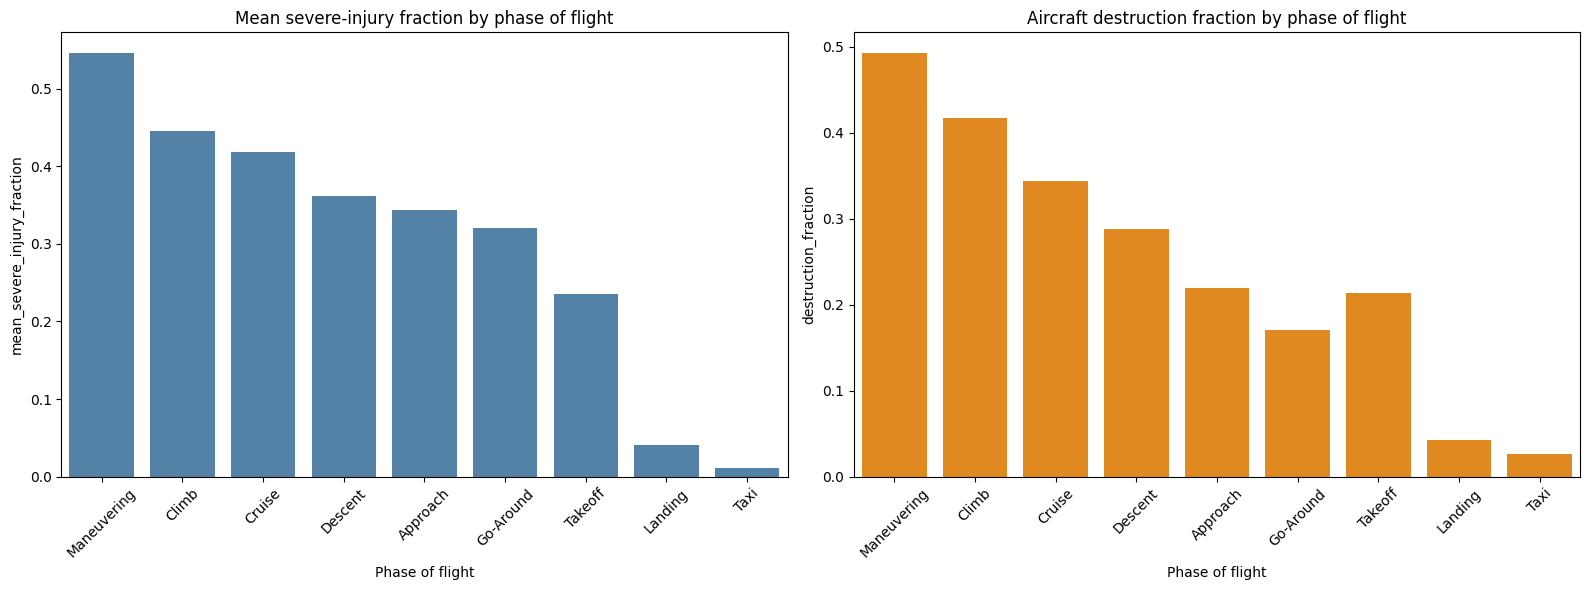

Interpretation: these are associations among reported accidents, not causal effects.
Weather and flight phase may be confounded by aircraft type, severity, operating context, and reporting completeness.


In [10]:
# Examine two factors: weather condition and phase of flight. 
# For each, summarize injury fraction and destruction fraction, requiring at least 100 accidents per group.

factor_specs = [
    ("Weather.Condition", "Weather condition"),
    ("Broad.phase.of.flight", "Phase of flight")
]
for col, label in factor_specs:
    factor_df = df.dropna(subset=[col]).copy()
    summary = (
        factor_df.groupby(col, observed=True)
        .agg(
            accident_count=("Event.Id", "size"),
            mean_severe_injury_fraction=("Fatal.Serious.Fraction", "mean"),
            destruction_fraction=("Aircraft.Destroyed", "mean")
        )
        .reset_index()
    )
    summary = summary[summary["accident_count"] >= 100].sort_values(
        "mean_severe_injury_fraction", ascending=False
    )
    print(f"\n{label}: summary (groups with at least 100 accidents)")
    display(summary)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    sns.barplot(data=summary, x=col, y="mean_severe_injury_fraction", ax=axes[0], color="steelblue")
    axes[0].set_title(f"Mean severe-injury fraction by {label.lower()}")
    axes[0].set_xlabel(label)
    axes[0].tick_params(axis="x", rotation=45)
    sns.barplot(data=summary, x=col, y="destruction_fraction", ax=axes[1], color="darkorange")
    axes[1].set_title(f"Aircraft destruction fraction by {label.lower()}")
    axes[1].set_xlabel(label)
    axes[1].tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()

print("Interpretation: these are associations among reported accidents, not causal effects.")
print("Weather and flight phase may be confounded by aircraft type, severity, operating context, and reporting completeness.")